# Exploratory analysis: monthly demand

Data: [Kaggle Store Item Demand Forecasting](https://www.kaggle.com/competitions/demand-forecasting-kernels-only/data), daily sales for 50 items across 10 stores, 2013–2017. Summed over stores to monthly sales per item, the same way `forecast.py` does.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
import forecast as f

y = f.load('../data/train.csv')
print(y.shape, 'months x items')
y.iloc[:5, :8]

(60, 50) months x items


item,1,2,3,4,5,6,7,8
date,,,,,,,,
2013-01-01,3794,10379,6345,3718,3103,10014,10151,13509
2013-02-01,3863,10338,6529,3920,3220,10401,10241,13478
2013-03-01,5190,13933,8546,5246,4307,13836,13957,18201
2013-04-01,5783,14938,9704,5834,4729,15250,15434,20078
2013-05-01,6298,17179,10755,6439,5392,16931,17179,22419


## 1. Trend and seasonality
Total demand peaks every July and bottoms out every January. The trend is upward, but growth is slowing.

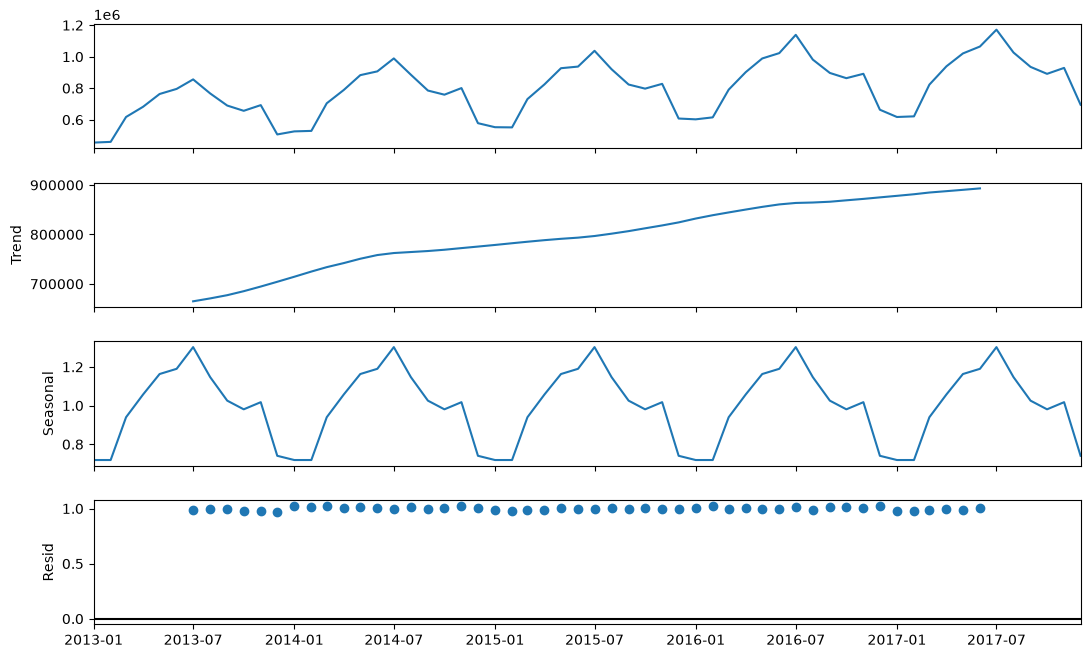

In [2]:
total = y.sum(axis=1)
seasonal_decompose(total, model='multiplicative', period=12).plot().set_size_inches(12, 7)

In [3]:
growth = total.groupby(total.index.year).sum().pct_change().mul(100).round(1)
growth.rename('YoY growth %').to_frame().T

date,2013,2014,2015,2016,2017
YoY growth %,NaN,15.0,4.4,8.6,3.6


## 2. Do items share the same seasonal shape?
Each item's monthly profile, divided by its own yearly average. If the lines overlap, one pooled model can learn the seasonality for every item at once. This is why `forecast.py` trains a single XGBoost model on scale-free ratios instead of 50 separate models.

max spread between items in any month: 0.028


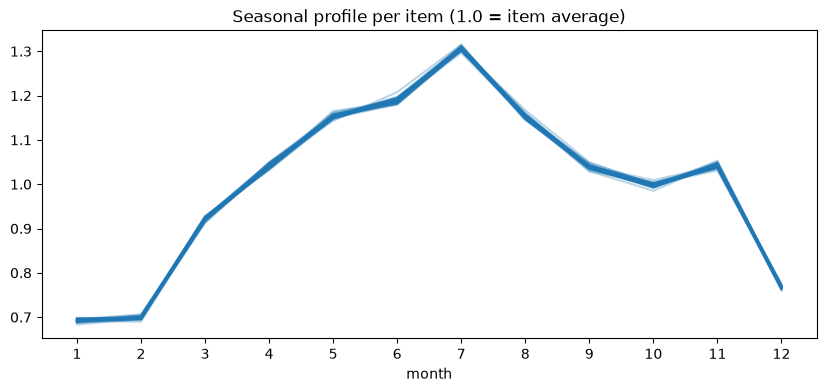

In [4]:
profile = y.groupby(y.index.month).mean()
profile = profile / profile.mean()
ax = profile.plot(legend=False, alpha=0.3, color='tab:blue', figsize=(10, 4), title='Seasonal profile per item (1.0 = item average)')
ax.set_xlabel('month'); ax.set_xticks(range(1, 13))
print('max spread between items in any month:', round((profile.max(axis=1) - profile.min(axis=1)).max(), 3))

## 3. Backtest results (from `python forecast.py`)
MAPE % averaged over 50 items, for each 6-month test window.

In [5]:
bt = pd.read_csv('../results/backtest.csv')
bt.pivot_table(index='model', columns='test_start', values='mape').round(2)

test_start,2016-07-01,2017-01-01,2017-07-01
model,,,
prophet,2.25,4.92,1.81
sarima,1.34,5.72,1.06
seasonal_naive,7.73,3.15,3.80
xgboost,2.85,3.85,1.70


The Jan–Jun 2017 window is the odd one out. Every model gets worse, and the naive baseline wins. Year-on-year growth fell from 8.6% in 2016 to 3.6% in 2017 (table in section 1). The models carried 2016's growth forward; SARIMA over-forecast every month of that window by 4–7%. The baseline assumes no growth, so it happened to land closer. A model trained on history can't anticipate a change in growth rate; in production this is what forecast monitoring and re-training are for.